In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
)

# Load preprocessed data
df = pd.read_csv("../data/processed/cs-processed.csv")

print(f"Rows: {len(df)}")
print(f"Target distribution: {df['SeriousDlqin2yrs'].value_counts(normalize=True).round(3)}")
print(f"Missing values:{df.isnull().sum()[df.isnull().sum() > 0]}")
# Define features and target
FEATURE_COLS = [
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents",
]

X = df[FEATURE_COLS]
y = df["SeriousDlqin2yrs"]

# Train/test split - stratified to preserve class balance in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print(f"Test set default rate: {y_test.mean():.3f}")

Rows: 146678
Target distribution: SeriousDlqin2yrs
0    0.94
1    0.06
Name: proportion, dtype: float64
Missing values:Series([], dtype: int64)
Training rows: 117342 | Test rows: 29336
Test set default rate: 0.060


In [5]:
# Scale features - logistic regression is sensitive to feature scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train a simple logistic regression baseline with no class weighting
model = LogisticRegression(
    max_iter=1000,
    random_state=42,
)
model.fit(X_train_scaled, y_train)

# Overall evaluation
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("=== Overall Performance ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, y_prob):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=["No Default", "Default"]))

=== Overall Performance ===
Accuracy: 0.940
ROC-AUC:  0.798

              precision    recall  f1-score   support

  No Default       0.94      1.00      0.97     27578
     Default       0.49      0.04      0.07      1758

    accuracy                           0.94     29336
   macro avg       0.72      0.52      0.52     29336
weighted avg       0.91      0.94      0.92     29336



In [6]:
# Reconstruct the test set with predictions
test_df = X_test.copy()
test_df["true_label"] = y_test.values
test_df["predicted_label"] = y_pred
test_df["predicted_prob"] = y_prob

# Define age groups
def assign_age_group(age):
    if age < 35:
        return "Under 35"
    elif age <= 60:
        return "35-60"
    else:
        return "Over 60"

test_df["age_group"] = test_df["age"].apply(assign_age_group)

print("Age group sizes:")
print(test_df["age_group"].value_counts())
def group_metrics(group_df):
    """Compute key fairness-relevant metrics for a subset of the test data."""
    true = group_df["true_label"]
    pred = group_df["predicted_label"]

    tn, fp, fn, tp = confusion_matrix(true, pred, labels=[0, 1]).ravel()

    accuracy = (tp + tn) / (tp + tn + fp + fn)
    predicted_default_rate = pred.mean()  # proportion predicted as default (1)
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0  # false positive rate
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0  # false negative rate

    return {
        "n": len(group_df),
        "default_rate": true.mean().round(3),
        "accuracy": round(accuracy, 3),
        "predicted_default_rate": round(predicted_default_rate, 3),
        "false_positive_rate": round(fpr, 3),
        "false_negative_rate": round(fnr, 3),
    }


results = {}
for group in ["Under 35", "35-60", "Over 60"]:
    subset = test_df[test_df["age_group"] == group]
    results[group] = group_metrics(subset)

metrics_df = pd.DataFrame(results).T
print("=== Group-Level Metrics ===")
print(metrics_df.to_string())

Age group sizes:
age_group
35-60       16635
Over 60      9039
Under 35     3662
Name: count, dtype: int64
=== Group-Level Metrics ===
                n  default_rate  accuracy  predicted_default_rate  false_positive_rate  false_negative_rate
Under 35   3662.0         0.102     0.897                   0.016                0.009                0.928
35-60     16635.0         0.069     0.931                   0.005                0.002                0.967
Over 60    9039.0         0.027     0.973                   0.000                0.000                0.996


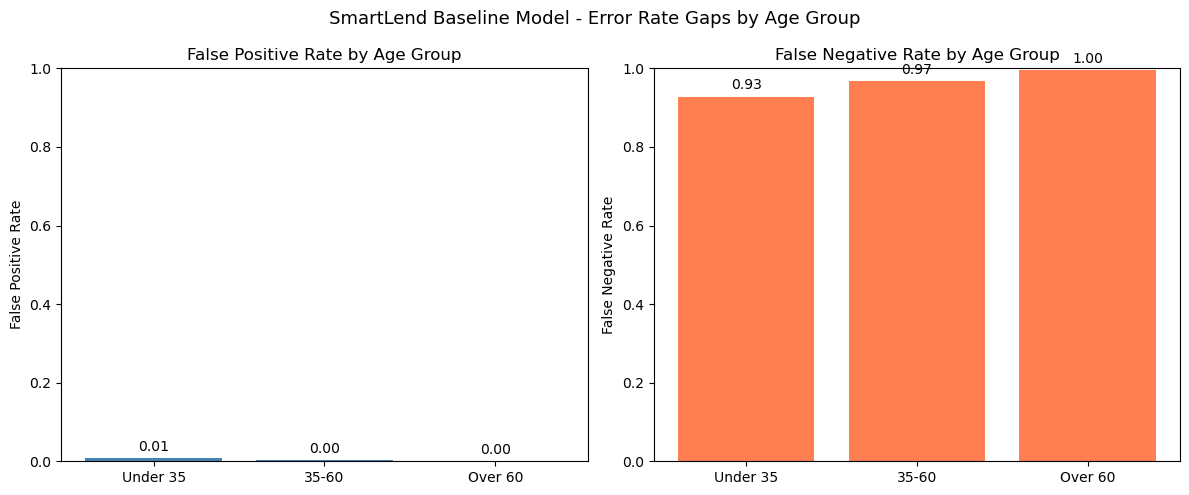

Chart saved to docs/fairness_fpr_fnr_by_age.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

groups = metrics_df.index.tolist()
x = range(len(groups))

axes[0].bar(x, metrics_df["false_positive_rate"], color="steelblue")
axes[0].set_xticks(x)
axes[0].set_xticklabels(groups)
axes[0].set_title("False Positive Rate by Age Group")
axes[0].set_ylabel("False Positive Rate")
axes[0].set_ylim(0, 1)
axes[0].bar_label(axes[0].containers[0], fmt="%.2f", padding=3)

axes[1].bar(x, metrics_df["false_negative_rate"], color="coral")
axes[1].set_xticks(x)
axes[1].set_xticklabels(groups)
axes[1].set_title("False Negative Rate by Age Group")
axes[1].set_ylabel("False Negative Rate")
axes[1].set_ylim(0, 1)
axes[1].bar_label(axes[1].containers[0], fmt="%.2f", padding=3)

plt.suptitle("SmartLend Baseline Model - Error Rate Gaps by Age Group", fontsize=13)
plt.tight_layout()
plt.savefig("../docs/fairness_fpr_fnr_by_age.png", dpi=150)
plt.show()

print("Chart saved to docs/fairness_fpr_fnr_by_age.png")